# 03 · Baseline models

Results of `scripts/run_baselines.py`, which this notebook reads (it does not retrain).

Setup:
- **Task:** Dropout vs. Graduate.
- **Sample:** the 3,478 students with semester records, the same students at every stage so stages are comparable.
- **Evaluation:** stratified 5-fold CV repeated 3 times (15 folds), with the same folds for every model and feature set.
- **Models:** logistic regression, random forest and gradient boosting (scikit-learn `HistGradientBoostingClassifier`), with class weights and fixed, untuned settings.
- **Preprocessing:** fit inside each training fold.
- **Metrics:** PR-AUC (main), ROC-AUC, and recall / precision / F1 at threshold 0.5.
- **Main runs:** exclude tuition and debtor status (data note 5); section 4 adds them.

Questions:
1. How much does each stage add?
2. Do the derived features help?
3. Can the models find dropouts who passed every semester-1 unit?
4. How much do tuition and debtor status change the results?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dropout import config
from dropout.plotting import MODEL_STYLE, MUTED, INK_SECONDARY, set_style, save

set_style()
TABLES = config.PROJECT_ROOT / "results" / "tables"
folds = pd.read_csv(TABLES / "cv_folds.csv")
sub = pd.read_csv(TABLES / "subgroup.csv")

STAGES = ["enrollment", "semester_1", "semester_2"]
MODELS = list(MODEL_STYLE)
KEYS = ["stage", "feature_set", "financial", "sample"]

def runs(stage=None, feature_set="raw", financial=False, sample="common"):
    m = (folds.feature_set == feature_set) & (folds.financial == financial) & (folds["sample"] == sample)
    return folds[m & (folds.stage == stage)] if stage else folds[m]

def mean_sd(df, metric):
    g = df.groupby(["stage", "model"])[metric]
    return (g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)).unstack("model")[MODELS]

def paired(base, other, metric="pr_auc"):
    """Fold-by-fold difference (other - base) on the same folds."""
    m = base.merge(other, on=["model", "repeat", "fold"], suffixes=("_base", "_new"))
    d = m[f"{metric}_new"] - m[f"{metric}_base"]
    return d.groupby(m["model"]).agg(mean_diff="mean", sd="std", folds_better=lambda x: f"{(x > 0).sum()}/{len(x)}").reindex(MODELS)

## 1. Stage curve

In [2]:
base = runs()
print("PR-AUC, mean ± sd over 15 folds (chance: 0.39)")
mean_sd(base, "pr_auc").reindex(STAGES)

PR-AUC, mean ± sd over 15 folds (chance: 0.39)


model,logreg,random_forest,gboost
stage,,,
enrollment,0.722 ± 0.015,0.725 ± 0.013,0.743 ± 0.011
semester_1,0.920 ± 0.011,0.917 ± 0.009,0.921 ± 0.010
semester_2,0.945 ± 0.010,0.945 ± 0.008,0.949 ± 0.007


In [3]:
base.groupby(["stage", "model"])[["roc_auc", "recall", "precision", "f1"]].mean().round(3).reindex(STAGES, level=0)

roc_auc  recall  precision     f1
stage      model                                           
enrollment gboost           0.812   0.707      0.660  0.683
           logreg           0.804   0.730      0.639  0.681
           random_forest    0.808   0.697      0.656  0.676
semester_1 gboost           0.929   0.808      0.868  0.837
           logreg           0.929   0.827      0.849  0.838
           random_forest    0.925   0.788      0.868  0.826
semester_2 gboost           0.951   0.840      0.909  0.873
           logreg           0.949   0.863      0.887  0.875
           random_forest    0.948   0.823      0.910  0.864

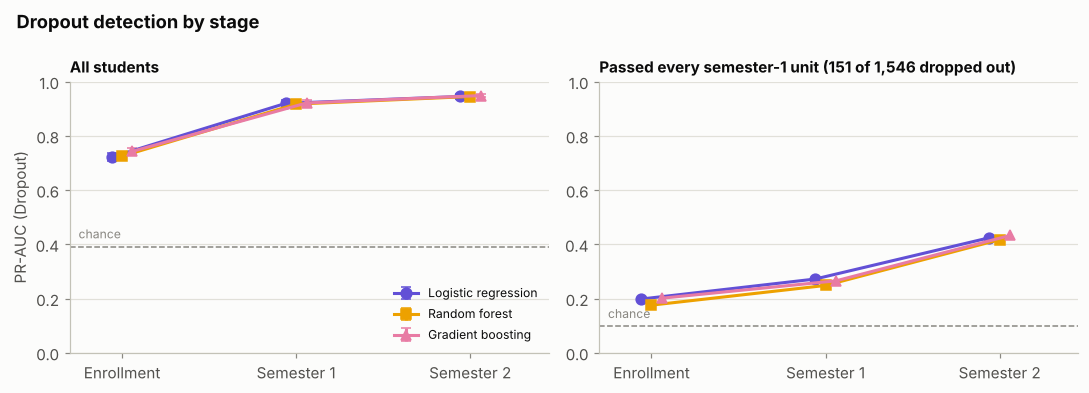

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
x = np.arange(len(STAGES))
labels = ["Enrollment", "Semester 1", "Semester 2"]
# panel 1: overall
for i, model in enumerate(MODELS):
    st = MODEL_STYLE[model]
    g = base[base.model == model].groupby("stage")["pr_auc"].agg(["mean", "std"]).reindex(STAGES)
    axes[0].errorbar(x + (i - 1) * 0.06, g["mean"], yerr=g["std"], color=st["color"], marker=st["marker"],
                     markersize=7, linewidth=2, capsize=3, label=st["label"])
# panel 2: still-passing subgroup
s = sub[(sub.feature_set == "raw") & (~sub.financial)]
for i, model in enumerate(MODELS):
    st = MODEL_STYLE[model]
    g = s[s.model == model].set_index("stage")["pr_auc"].reindex(STAGES)
    axes[1].plot(x + (i - 1) * 0.06, g, color=st["color"], marker=st["marker"], markersize=7, linewidth=2, label=st["label"])
for ax, title, chance in [(axes[0], "All students", 1421 / 3630), (axes[1], "Passed every semester-1 unit (151 of 1,546 dropped out)", 151 / 1546)]:
    ax.axhline(chance, color=MUTED, linestyle="--", linewidth=1)
    ax.text(-0.25, chance + 0.02, "chance", va="bottom", color=MUTED, fontsize=8)
    ax.set_xticks(x, labels)
    ax.set_xlim(-0.3, 2.45)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("PR-AUC (Dropout)")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Dropout detection by stage", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "fig4_stage_curve")

Semester-1 data give the largest gain: PR-AUC rises from 0.72–0.74 at enrollment to about 0.92, and semester 2 adds about 0.03 more. The three models are within 0.02 of each other at every stage, and from semester 1 on, logistic regression is as good as the tree models.

## 2. Derived features
Fold-by-fold change in PR-AUC from adding the core and extended features (`features.py`) to the raw columns.

In [5]:
rows = []
for stage in ["semester_1", "semester_2"]:
    for fs in ["core", "extended"]:
        rows.append(paired(runs(stage), runs(stage, fs)).assign(stage=stage, feature_set=fs))
pd.concat(rows).reset_index().set_index(["stage", "feature_set", "model"]).round(4)

mean_diff      sd folds_better
stage      feature_set model                                        
semester_1 core        logreg           -0.0007  0.0023         7/15
                       random_forest     0.0062  0.0041        15/15
                       gboost            0.0012  0.0049        10/15
           extended    logreg           -0.0010  0.0036         8/15
                       random_forest     0.0050  0.0047        14/15
                       gboost            0.0012  0.0048         9/15
semester_2 core        logreg            0.0005  0.0017         8/15
                       random_forest     0.0045  0.0032        14/15
                       gboost            0.0015  0.0026        11/15
           extended    logreg            0.0001  0.0026         6/15
                       random_forest     0.0041  0.0031        13/15
                       gboost            0.0011  0.0032        11/15

In [6]:
s = sub[~sub.financial & sub.stage.isin(["semester_1", "semester_2"])]
s.pivot_table(index=["stage", "model"], columns="feature_set", values="pr_auc").reindex(columns=["raw", "core", "extended"]).round(3)

feature_set                 raw   core  extended
stage      model                                
semester_1 gboost         0.266  0.245     0.239
           logreg         0.272  0.260     0.258
           random_forest  0.248  0.235     0.216
semester_2 gboost         0.433  0.416     0.405
           logreg         0.424  0.416     0.412
           random_forest  0.417  0.403     0.398

The derived features change PR-AUC by less than 0.01. Random forest gains slightly (+0.004 to +0.006, better in 13–15 of 15 folds); logistic regression and gradient boosting are unchanged. Within the still-passing subgroup they slightly lower PR-AUC.

The derived features are functions of columns the models already see, so with these models they add little new information. The trajectory hypothesis is not supported in this form.

## 3. Still-passing subgroup
Students who passed every semester-1 unit: 1,546 students, 151 of whom dropped out (9.8%). Recall is shown with the false-alarm rate (share of this group's graduates flagged), because recall alone rewards flagging everyone.

In [7]:
s = sub[(sub.feature_set == "raw") & (~sub.financial)]
s.set_index(["stage", "model"])[["pr_auc", "roc_auc", "recall", "false_alarm_rate"]].reindex(STAGES, level=0).round(3)

pr_auc  roc_auc  recall  false_alarm_rate
stage      model                                                   
enrollment logreg          0.198    0.652   0.530             0.266
           random_forest   0.176    0.642   0.428             0.221
           gboost          0.202    0.659   0.477             0.229
semester_1 logreg          0.272    0.692   0.137             0.020
           random_forest   0.248    0.678   0.113             0.018
           gboost          0.266    0.694   0.124             0.018
semester_2 logreg          0.424    0.766   0.309             0.031
           random_forest   0.417    0.762   0.256             0.023
           gboost          0.433    0.778   0.287             0.025

Within this group, ranking improves with each stage (ROC-AUC about 0.65 → 0.69 → 0.77; PR-AUC 0.20 → 0.27 → 0.43, against 0.10 by chance).

At threshold 0.5 the semester-stage models flag few of these dropouts (recall 0.11–0.31) but raise few false alarms (2–3%). The enrollment models catch about half, but only by flagging about a quarter of the group's graduates. A lower threshold or a dedicated model for this group is a follow-up.

## 4. Tuition and debtor status
Fold-by-fold change from adding the two variables whose recording time is unknown.

In [8]:
rows = [paired(runs(stage), runs(stage, financial=True)).assign(stage=stage) for stage in STAGES]
pd.concat(rows).reset_index().set_index(["stage", "model"]).round(4)

mean_diff      sd folds_better
stage      model                                        
enrollment logreg            0.1025  0.0140        15/15
           random_forest     0.0992  0.0138        15/15
           gboost            0.0871  0.0143        15/15
semester_1 logreg            0.0185  0.0066        15/15
           random_forest     0.0179  0.0043        15/15
           gboost            0.0165  0.0062        15/15
semester_2 logreg            0.0100  0.0064        15/15
           random_forest     0.0095  0.0046        15/15
           gboost            0.0081  0.0040        15/15

In [9]:
s = sub[sub.feature_set == "raw"].pivot_table(index=["stage", "model"], columns="financial", values=["pr_auc", "recall"])
s.columns = [f"{m} ({'with' if f else 'without'})" for m, f in s.columns]
s.reindex(STAGES, level=0).round(3)

pr_auc (without)  ...  recall (with)
stage      model                            ...               
enrollment gboost                    0.202  ...          0.519
           logreg                    0.198  ...          0.539
           random_forest             0.176  ...          0.475
semester_1 gboost                    0.266  ...          0.260
           logreg                    0.272  ...          0.285
           random_forest             0.248  ...          0.234
semester_2 gboost                    0.433  ...          0.380
           logreg                    0.424  ...          0.371
           random_forest             0.417  ...          0.351

[9 rows x 4 columns]

In [10]:
full = folds[folds["sample"] == "full"].groupby(["financial", "model"])["pr_auc"].mean().unstack()[MODELS]
common = runs("enrollment").groupby("model")["pr_auc"].mean()[MODELS]
print("Enrollment-stage PR-AUC, all 3,630 students vs. the 3,478 used above")
pd.concat([full.rename(index={False: "all students, without", True: "all students, with"}),
           common.to_frame("common sample, without").T]).round(3)

Enrollment-stage PR-AUC, all 3,630 students vs. the 3,478 used above


model,logreg,random_forest,gboost
"all students, without",0.722,0.727,0.739
"all students, with",0.822,0.821,0.826
"common sample, without",0.722,0.725,0.743


Adding tuition and debtor status raises PR-AUC in every fold at every stage: +0.09 to +0.10 at enrollment, +0.02 at semester 1 and +0.01 at semester 2. Within the still-passing group the gain is larger (semester-1 PR-AUC 0.27 → 0.40).

Because their recording time is unknown (data note 5), part of this gain may be leakage. Excluding the 152 students without semester records does not change the enrollment results (last table).

## Summary

1. **Semester-1 data matter most.** PR-AUC rises from about 0.73 at enrollment to 0.92 after semester 1 and 0.95 after semester 2.
2. **Model choice matters little.** All three models are within 0.02, and logistic regression matches the tree models after semester 1.
3. **The derived features add less than 0.01 PR-AUC** and do not help with the still-passing group.
4. **Still-passing dropouts are hard to find.** Within that group, PR-AUC is 0.27 after semester 1 and 0.43 after semester 2 (chance: 0.10).
5. **Tuition and debtor status add 0.09–0.10 PR-AUC at enrollment** and help most in the still-passing group. Whether this is real signal or leakage depends on when they were recorded.

**Next:** tuning (nested CV), a neural network, feature importance, and a threshold or model aimed at the still-passing group.